In [1]:
#IMPORT LIBRARIES AND LOAD DATA

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

pd.set_option('display.max_colwidth', 100)
plt.rcParams['figure.dpi'] = 100

# Change this path if your CSV is stored somewhere else
df = pd.read_csv(r"C:\Users\durga\Downloads\BA_AirlineReviews.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (3819, 20)


,Column1,OverallRating,ReviewHeader,Name,Datetime,VerifiedReview,ReviewBody,TypeOfTraveller,SeatType,Route,DateFlown,SeatComfort,CabinStaffService,GroundService,ValueForMoney,Recommended,Aircraft,Food&Beverages,InflightEntertainment,Wifi&Connectivity
0,0,1.0,"""Service level far worse then Ryanair""",L Keele,19th November 2023,True,4 Hours before takeoff we received a Mail stating a cryptic message that there are disruptions t...,Couple Leisure,Economy Class,London to Stuttgart,01-11-2023,1.0,1.0,1.0,1.0,no,NaN,NaN,NaN,NaN
1,1,3.0,"""do not upgrade members based on status""",Austin Jones,19th November 2023,True,I recently had a delay on British Airways from BRU to LHR that was due to staff shortages. They ...,Business,Economy Class,Brussels to London,01-11-2023,2.0,3.0,1.0,2.0,no,A320,1.0,2.0,2.0
2,2,8.0,"""Flight was smooth and quick""",M A Collie,16th November 2023,False,"Boarded on time, but it took ages to get to the runway due to congestion. Flight was smooth and ...",Couple Leisure,Business Class,London Heathrow to Dublin,01-11-2023,3.0,3.0,4.0,3.0,yes,A320,4.0,NaN,NaN
3,3,1.0,"""Absolutely hopeless airline""",Nigel Dean,16th November 2023,True,"5 days before the flight, we were advised by BA that it had been cancelled and asked us to reboo...",Couple Leisure,Economy Class,London to Dublin,01-12-2022,3.0,3.0,1.0,1.0,no,NaN,NaN,NaN,NaN
4,4,1.0,"""Customer Service is non existent""",Gaylynne Simpson,14th November 2023,False,"We traveled to Lisbon for our dream vacation, a cruise to Portugal and Spain. Our friends did no...",Couple Leisure,Economy Class,London to Lisbon,01-11-2023,1.0,1.0,1.0,1.0,no,NaN,1.0,1.0,1.0


In [2]:
#COLUMN NAMES

df.columns

Index(['Column1', 'OverallRating', 'ReviewHeader', 'Name', 'Datetime',
       'VerifiedReview', 'ReviewBody', 'TypeOfTraveller', 'SeatType', 'Route',
       'DateFlown', 'SeatComfort', 'CabinStaffService', 'GroundService',
       'ValueForMoney', 'Recommended', 'Aircraft', 'Food&Beverages',
       'InflightEntertainment', 'Wifi&Connectivity'],
      dtype='object')

In [3]:
#DATASET INFORMATION

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3819 entries, 0 to 3818
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Column1                3792 non-null   object 
 1   OverallRating          3696 non-null   float64
 2   ReviewHeader           3720 non-null   object 
 3   Name                   3706 non-null   object 
 4   Datetime               3705 non-null   object 
 5   VerifiedReview         3687 non-null   object 
 6   ReviewBody             3706 non-null   object 
 7   TypeOfTraveller        2856 non-null   object 
 8   SeatType               3627 non-null   object 
 9   Route                  2854 non-null   object 
 10  DateFlown              2833 non-null   object 
 11  SeatComfort            3508 non-null   float64
 12  CabinStaffService      3496 non-null   float64
 13  GroundService          2775 non-null   float64
 14  ValueForMoney          3613 non-null   float64
 15  Reco

In [4]:
#DATA TYPES

df.dtypes

Column1                   object
OverallRating            float64
ReviewHeader              object
Name                      object
Datetime                  object
VerifiedReview            object
ReviewBody                object
TypeOfTraveller           object
SeatType                  object
Route                     object
DateFlown                 object
SeatComfort              float64
CabinStaffService        float64
GroundService            float64
ValueForMoney            float64
Recommended               object
Aircraft                  object
Food&Beverages           float64
InflightEntertainment    float64
Wifi&Connectivity        float64
dtype: object

In [5]:
#OVERALL RATING COUNTS

df["OverallRating"].value_counts().sort_index()

OverallRating
1.0     865
2.0     424
3.0     406
4.0     254
5.0     234
6.0     190
7.0     313
8.0     370
9.0     310
10.0    330
Name: count, dtype: int64

In [6]:
#MISSING VALUES CHECK

missing_values = df.isnull().sum().sort_values(ascending = False)
print(missing_values)

Wifi&Connectivity        3226
Aircraft                 1951
InflightEntertainment    1330
GroundService            1044
DateFlown                 986
Route                     965
TypeOfTraveller           963
Food&Beverages            580
CabinStaffService         323
SeatComfort               311
ValueForMoney             206
Recommended               200
SeatType                  192
VerifiedReview            132
OverallRating             123
Datetime                  114
ReviewBody                113
Name                      113
ReviewHeader               99
Column1                    27
dtype: int64


In [7]:
# DATA PREPARATION AND FEATURE ENGINEERING
  # CONVERT RATING COLUMNS TO NUMERIC

rating_cols = [
    'OverallRating',
    'SeatComfort',
    'CabinStaffService',
    'GroundService',
    'ValueForMoney',
    'Food&Beverages',
    'InflightEntertainment',
    'Wifi&Connectivity'
]

for col in rating_cols:
    if col in df.columns:
        df[col]=pd.to_numeric(df[col],errors="coerce")

In [8]:
# REVIEW LENGTH 

df["review_length"]=(
    df["ReviewBody"]
    .fillna(" ")
    .astype(str)
    .str.split()
    .str.len()
)

df[["ReviewBody","review_length"]].head()

,ReviewBody,review_length
0,4 Hours before takeoff we received a Mail stating a cryptic message that there are disruptions t...,125
1,I recently had a delay on British Airways from BRU to LHR that was due to staff shortages. They ...,206
2,"Boarded on time, but it took ages to get to the runway due to congestion. Flight was smooth and ...",54
3,"5 days before the flight, we were advised by BA that it had been cancelled and asked us to reboo...",255
4,"We traveled to Lisbon for our dream vacation, a cruise to Portugal and Spain. Our friends did no...",172


In [9]:
# IDENTIFY CRITICAL REVIEWS

df["is_critical"] = (
    df["OverallRating"].le(3)
    .fillna(False)
    .astype(int)
)
df[["OverallRating" , "is_critical" ]].head()

,OverallRating,is_critical
0,1.0,1
1,3.0,1
2,8.0,0
3,1.0,1
4,1.0,1


In [10]:
# CREATE RATING CATEGORIES

df['rating_category'] = np.select(
    [
        df['OverallRating'].le(3),
        df['OverallRating'].between(4, 6),
        df['OverallRating'].between(7, 10)
    ],
    [
        'Critical',
        'Neutral/Mixed',
        'Positive'
    ],
    default='Missing'
)

df['rating_category'].value_counts()

rating_category
Critical         1695
Positive         1323
Neutral/Mixed     678
Missing           123
Name: count, dtype: int64

In [11]:
# RATING COUNTS AND PERCENTAGES

valid_ratings = df['OverallRating'].dropna()

critical_count = (valid_ratings <= 3).sum()
neutral_count = (
    (valid_ratings >= 4) & (valid_ratings <= 6)
).sum()
positive_count = (valid_ratings >= 7).sum()

total_valid = len(valid_ratings)

print("Valid ratings:", total_valid)
print("Critical reviews:", critical_count)
print("Neutral/Mixed reviews:", neutral_count)
print("Positive reviews:", positive_count)

Valid ratings: 3696
Critical reviews: 1695
Neutral/Mixed reviews: 678
Positive reviews: 1323


In [12]:
# CALCULATE PERCENTAGES

if total_valid > 0:
    critical_percentage = critical_count / total_valid * 100
    neutral_percentage = neutral_count / total_valid * 100
    positive_percentage = positive_count / total_valid * 100

    print(f"Critical: {critical_percentage:.2f}%")
    print(f"Neutral/Mixed: {neutral_percentage:.2f}%")
    print(f"Positive: {positive_percentage:.2f}%")
else:
    print("No valid overall ratings found.")

Critical: 45.86%
Neutral/Mixed: 18.34%
Positive: 35.80%


In [13]:
# FILTER CRITICAL REVIEWS 

critical_reviews = df[
    df['is_critical'] == 1
].copy()

print("Critical reviews:", len(critical_reviews))

critical_reviews.head()

Critical reviews: 1695


,Column1,OverallRating,ReviewHeader,Name,Datetime,VerifiedReview,ReviewBody,TypeOfTraveller,SeatType,Route,...,GroundService,ValueForMoney,Recommended,Aircraft,Food&Beverages,InflightEntertainment,Wifi&Connectivity,review_length,is_critical,rating_category
0,0,1.0,"""Service level far worse then Ryanair""",L Keele,19th November 2023,True,4 Hours before takeoff we received a Mail stating a cryptic message that there are disruptions t...,Couple Leisure,Economy Class,London to Stuttgart,...,1.0,1.0,no,NaN,NaN,NaN,NaN,125,1,Critical
1,1,3.0,"""do not upgrade members based on status""",Austin Jones,19th November 2023,True,I recently had a delay on British Airways from BRU to LHR that was due to staff shortages. They ...,Business,Economy Class,Brussels to London,...,1.0,2.0,no,A320,1.0,2.0,2.0,206,1,Critical
3,3,1.0,"""Absolutely hopeless airline""",Nigel Dean,16th November 2023,True,"5 days before the flight, we were advised by BA that it had been cancelled and asked us to reboo...",Couple Leisure,Economy Class,London to Dublin,...,1.0,1.0,no,NaN,NaN,NaN,NaN,255,1,Critical
4,4,1.0,"""Customer Service is non existent""",Gaylynne Simpson,14th November 2023,False,"We traveled to Lisbon for our dream vacation, a cruise to Portugal and Spain. Our friends did no...",Couple Leisure,Economy Class,London to Lisbon,...,1.0,1.0,no,NaN,1.0,1.0,1.0,172,1,Critical
5,5,1.0,"""I can’t imagine a worst airline""",A Narden,12th November 2023,True,Booked a flight from Bucharest to Manchester with a 2h 45’ layover at Heathrow. Flight was delay...,Solo Leisure,Economy Class,Bucharest to Manchester via London,...,1.0,1.0,no,A320,1.0,1.0,NaN,203,1,Critical


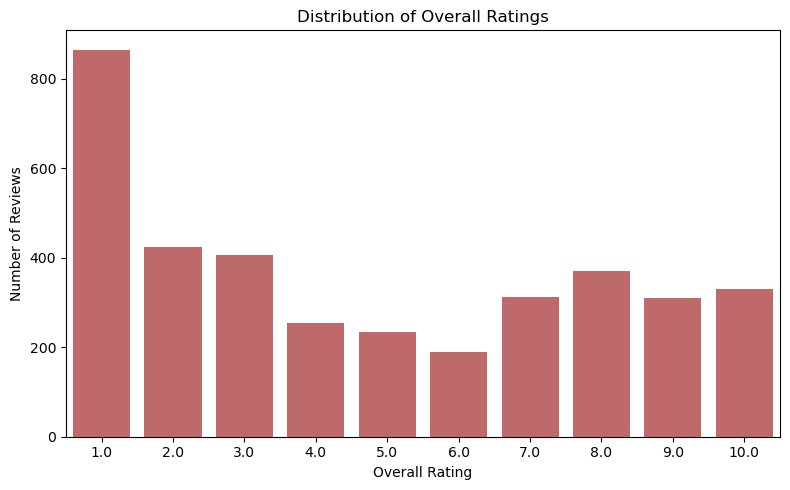

In [14]:
# VISUAL ANALYSIS
 # OVERALL RATING DISTRIBUTION

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='OverallRating',
    color='indianred'
)

plt.title('Distribution of Overall Ratings')
plt.xlabel('Overall Rating')
plt.ylabel('Number of Reviews')
plt.tight_layout()
plt.show()


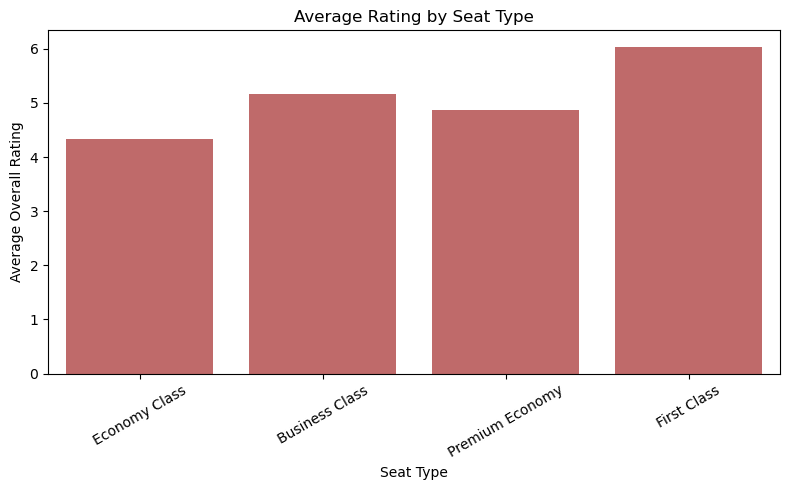

In [15]:
# AVERAGE RATING BY SEAT TYPE

seat_types = [
    'Economy Class',
    'Business Class',
    'Premium Economy',
    'First Class'
]

plot_df = df[
    df['SeatType'].isin(seat_types)
    & df['OverallRating'].notna()
].copy()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=plot_df,
    x='SeatType',
    y='OverallRating',
    order=seat_types,
    color='indianred',
    errorbar=None
)

plt.title('Average Rating by Seat Type')
plt.xlabel('Seat Type')
plt.ylabel('Average Overall Rating')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

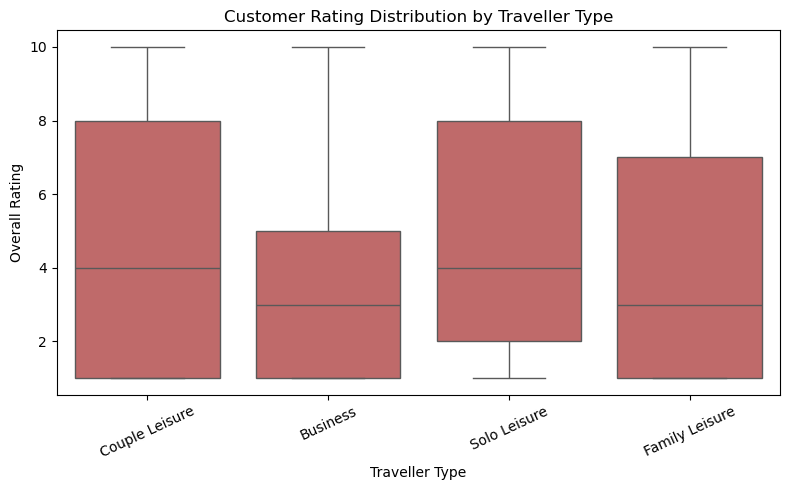

In [16]:
# RATING DISTRIBUTION BY TRAVELLER TYPE

valid_travellers = [
    'Couple Leisure',
    'Solo Leisure',
    'Family Leisure',
    'Business'
]

plot_df = df[
    df['TypeOfTraveller'].astype('string').str.strip().isin(valid_travellers)
    & df['OverallRating'].notna()
].copy()

if not plot_df.empty:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=plot_df,
        x='TypeOfTraveller',
        y='OverallRating',
        color='indianred'
    )

    plt.title('Customer Rating Distribution by Traveller Type')
    plt.xlabel('Traveller Type')
    plt.ylabel('Overall Rating')
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()
else:
    print("No rows matched the selected traveller categories.")
    print(df['TypeOfTraveller'].value_counts(dropna=False).head(15))

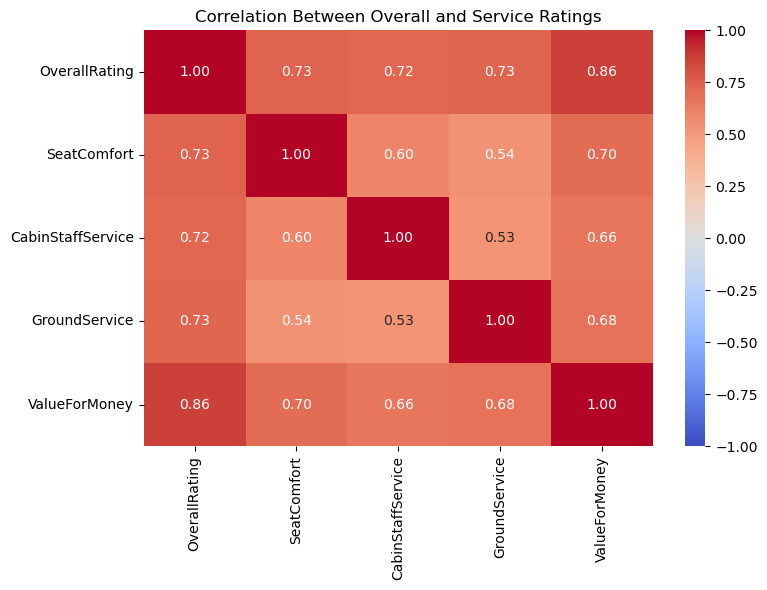

In [17]:
# CORRELATION BETWEEN OVERALL AND SERVICE RATINGS

service_cols = [
    'OverallRating',
    'SeatComfort',
    'CabinStaffService',
    'GroundService',
    'ValueForMoney'
]

corr = df[service_cols].corr(method='spearman')

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f'
)

plt.title('Correlation Between Overall and Service Ratings')
plt.tight_layout()
plt.show()

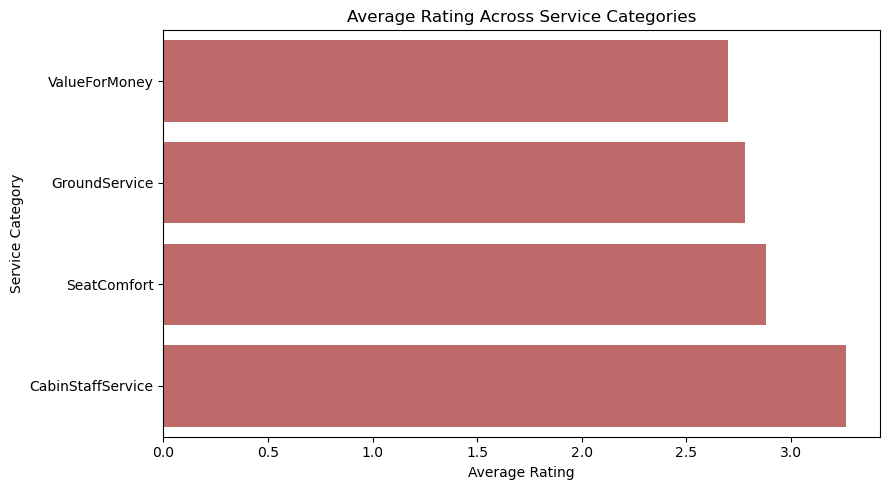

Average service ratings:
ValueForMoney        2.699972
GroundService        2.780901
SeatComfort          2.877993
CabinStaffService    3.262014
dtype: float64


In [18]:
# AVERAGE RATING ACROSS SERVICE CATEGORIES

service_cols = [
    'SeatComfort',
    'CabinStaffService',
    'GroundService',
    'ValueForMoney'
]

avg_ratings = df[service_cols].mean().sort_values()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=avg_ratings.values,
    y=avg_ratings.index,
    color='indianred',
    errorbar=None
)

plt.title('Average Rating Across Service Categories')
plt.xlabel('Average Rating')
plt.ylabel('Service Category')
plt.tight_layout()
plt.show()

print("Average service ratings:")
print(avg_ratings)

In [19]:
#NEGATIVE LANGUAGE COMPLAINT EXPLORATION
  # PREPARE CRITICAL REVIEW TEXT

critical_text = (
    critical_reviews['ReviewBody']
    .dropna()
    .astype(str)
)

print("Critical reviews with text:", len(critical_text))

Critical reviews with text: 1686


In [20]:
# COUNT NEGATIVE WORDS USING NLTK

import nltk

nltk.download('opinion_lexicon')

from nltk.corpus import opinion_lexicon

negative_words = set(opinion_lexicon.negative())

words = re.findall(
    r"\b[a-zA-Z']+\b",
    " ".join(critical_text).lower()
)

filtered = [word for word in words if word in negative_words]

print(Counter(filtered).most_common(20))

[nltk_data] Downloading package opinion_lexicon to
[nltk_data]     C:\Users\durga\AppData\Roaming\nltk_data...
[nltk_data]   Package opinion_lexicon is already up-to-date!


[('poor', 352), ('delayed', 336), ('worst', 212), ('delay', 196), ('bad', 177), ('uncomfortable', 172), ('lost', 160), ('problem', 148), ('awful', 144), ('terrible', 141), ('missed', 124), ('rude', 123), ('worse', 112), ('refused', 103), ('issue', 99), ('appalling', 98), ('disappointed', 97), ('cramped', 97), ('hard', 93), ('wrong', 92)]


In [21]:
# COUNT SELECTED COMPLAIANT KEYWORDS

negative_keywords = [
    'delayed',
    'poor',
    'worst',
    'refund',
    'rude',
    'lost',
    'bad',
    'cancelled'
]

pattern = '|'.join(
    re.escape(word) for word in negative_keywords
)

keyword_reviews = critical_reviews[
    critical_reviews['ReviewBody'].str.contains(
        pattern,
        case=False,
        na=False,
        regex=True
    )
].copy()

print(
    "Critical reviews containing selected keywords:",
    len(keyword_reviews)
)

keyword_reviews[['OverallRating', 'ReviewBody']].head(5)

Critical reviews containing selected keywords: 1024


,OverallRating,ReviewBody
1,3.0,I recently had a delay on British Airways from BRU to LHR that was due to staff shortages. They ...
3,1.0,"5 days before the flight, we were advised by BA that it had been cancelled and asked us to reboo..."
5,1.0,Booked a flight from Bucharest to Manchester with a 2h 45’ layover at Heathrow. Flight was delay...
8,2.0,"Angry, disappointed, and unsatisfied. My route was from London to Atlanta. My suitcase was not b..."
9,3.0,"As an infrequent flyer, British Airways was always my first choice. With some reassurance and co..."


In [22]:
# SELECT THE 10 LONGEST KEYWORD-MATCHED CRITICAL REVIEWS

top_reviews = (
    keyword_reviews
    .assign(
        review_length=lambda x:
        x['ReviewBody'].fillna('').astype(str).str.split().str.len()
    )
    .sort_values('review_length', ascending=False)
    .head(10)
)

top_reviews[['OverallRating', 'ReviewBody', 'review_length']]

,OverallRating,ReviewBody,review_length
793,2.0,Hong Kong to Copenhagen via London. The whole experience is a nightmare to me and my wife. My wi...,654
2413,2.0,Vancouver to Barcelona via Heathrow with British Airways. I would like to start this review by s...,653
90,1.0,Terrible Experience with British Airways. I booked a flight with BA to travel from Gibraltar to ...,639
1576,2.0,Naples to Gatwick. I used to admire and love BA. I now no longer admire it but dislike it and am...,628
1507,1.0,On a flight from Bangkok to London and you'll have some locals and holiday makers that wish to h...,626
2633,3.0,"I have flown British Airways Business Class and was pleased with Lounge, food service, Elemis Sp...",622
209,1.0,The usual shambolic unfolding that BA has now unfortunately been come to known for. We had a lon...,618
1142,1.0,"London to Amsterdam. BA's service has gone notably downhill in the past couple of years, but ton...",612
67,1.0,I arrived at the airport about 2.5 hours before takeoff to have more than about time to get chec...,605
1381,3.0,Vancouver to Edinburgh via London was the worst travel experience I have had. I was travelling w...,599


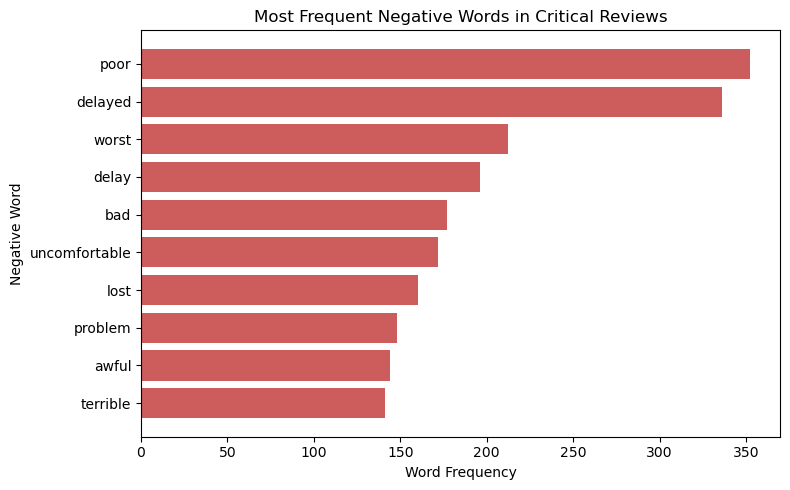

In [23]:
# PLOTTING THE MOST FREQUENT NEGATIVE WORDS

top_words = Counter(filtered).most_common(10)

if top_words:
    words, counts = zip(*top_words)

    plt.figure(figsize=(8, 5))
    plt.barh(words[::-1], counts[::-1], color='indianred')

    plt.title('Most Frequent Negative Words in Critical Reviews')
    plt.xlabel('Word Frequency')
    plt.ylabel('Negative Word')
    plt.tight_layout()
    plt.show()
else:
    print("No negative words found.")

In [24]:
#GEN AI APOLOGY EMAIL GENERATION

%pip install -q langchain-groq

Note: you may need to restart the kernel to use updated packages.


In [25]:
# IMPORT GROQ INTEGRATION

from langchain_groq import ChatGroq
from getpass import getpass

In [30]:
# ENTER API KEY

groq_api_key = getpass("Enter your Groq API key: ")

Enter your Groq API key:  ········


In [31]:
# INITIALIZING THE LANGUAGE MODEL

llm_model = ChatGroq(
    model="openai/gpt-oss-120b",
    groq_api_key=groq_api_key,
    temperature=0.3
)

In [32]:
# CREATE THE APOLOGY EMAIL FUNCTION

def generate_apology(review):
    if pd.isna(review) or not str(review).strip():
        return "No review text available."

    prompt = f"""
You are a professional customer relations assistant
for British Airways.

Write a sincere, concise, professional apology email
based on the customer's review.

CUSTOMER REVIEW:
{review}

INSTRUCTIONS:
1. Start with a suitable subject line.
2. Use "Dear Customer," unless the customer's name
   is explicitly provided in the review.
3. Acknowledge the specific concern mentioned.
4. Use natural, empathetic, professional English.
5. Do not repeat the entire review.
6. Do not invent names or personal details.
7. Do not claim an investigation, escalation, refund,
   compensation or follow-up has already happened
   unless the supplied information confirms it.
8. Do not promise a deadline or an outcome.
9. Use "we", "our" and "us" on behalf of the team.
10. End exactly with:

Kind regards,
Customer Relations Team
British Airways

Return only the email draft.
"""

    response = llm_model.invoke(prompt)
    return response.content

In [34]:
# GENERATE DRAFTS FOR SELECTED REVIEWS

for _, row in top_reviews.iterrows():
    review = row['ReviewBody']

    print("Customer rating:", row['OverallRating'])
    print(generate_apology(review))
    print("-" * 60)

Customer rating: 2.0
Subject: Sincere Apology for the Difficulties You Experienced with Your Baggage

Dear Customer,

We are truly sorry for the distress and inconvenience you and your wife endured during your recent journey from Hong Kong to Copenhagen via London. It is unacceptable that your luggage was mishandled, that communication with the handling agent was confusing, and that you were left without your belongings for several days.

We understand how frustrating it must have been to receive conflicting information, to have delivery instructions ignored, and to spend valuable time at the airport without resolution. Please accept our sincere apologies for the anxiety and inconvenience this caused you and for the impact on your travel experience.

Your feedback highlights serious shortcomings in the handling of baggage and the support provided, and we will share your experience with the relevant teams to ensure such lapses are addressed.

Thank you for bringing this matter to our at

In [35]:
# final validation 
  # check final counts

print("Dataset rows:", len(df))
print("Valid overall ratings:", total_valid)
print("Critical reviews:", critical_count)
print("Critical reviews with selected keywords:", len(keyword_reviews))
print("Reviews selected for AI drafts:", len(top_reviews))

print("\nRating percentages:")
print(f"Critical: {critical_percentage:.2f}%")
print(f"Neutral/Mixed: {neutral_percentage:.2f}%")
print(f"Positive: {positive_percentage:.2f}%")

Dataset rows: 3819
Valid overall ratings: 3696
Critical reviews: 1695
Critical reviews with selected keywords: 1024
Reviews selected for AI drafts: 10

Rating percentages:
Critical: 45.86%
Neutral/Mixed: 18.34%
Positive: 35.80%


In [36]:
df.to_csv("BA_AirlineReviews_Analyzed.csv", index=False)